# Intelligent Agents: Reflex-Based Agents for GridHunt (Multi-agent Environment)

Student Name: Lâm Tú Nhi

I have used the following AI tools: Claude, ChatGPT

I understand that my submission needs to be my own work: Nhi

## Learning Outcomes

* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.

## Instructions

Total Points: 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook.
### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

## Introduction

![GridHunt Image](gridhunt.png)

Gridhunt is a small educational game that helps you practice implementing simple agent functions. It is a modified Python reimplementation of Gridhunt2. 

The objective of gridhunt is to implement an intelligent agent, the hunter, who can catch a monster faster than all other hunters. Gridhunt uses a $n \times n$ arena consisting of a grid of tiles. Gridhunt is a turn-based game, and several hunter agents and the monster agent move around in the arena. A hunter catches the monster if she/he moves on the same square the monster currently occupies. The hunters compete fow who catches the monster first. If the monster survives the maximum number of steps for the game, then the monster wins.

## PEAS Description of Gridhunt

__Performance Measure:__ The performance is measured as the number of steps the hunter uses to catch the monster. Catching the monster means to be on the same square.

__Environment:__ An arena with $n \times n$ squares. At the beginning the monster and the hunters are randomly placed in the arena environment. The hunters and the monster
    can move around, but cannot leave the arena. Since there are three agents involved, this is a competitive multi-agent environment.

__Actuators:__ The agent can move to an adjacent square using actions "north", "east", "west", and "south", or teleport which will move the agent 
    to a random square in the arena.

__Sensors:__ The agent can always see its location in the arena and the location of the monster.  

## The Arena Environment

The environment manages the location of the agents (hunter and monster). It initially places them in a random location and then provides them in every step with percepts (the location of the hunter and the monster) and asks them for their action. 

__A Note on positions:__
The arena is implemented as an array with row and column indices representing the position.
Positions are stored in a numpy array where `pos[0]` is the row index and `pos[1]` is the column index in the arena. North means up in this array, that is the row index gets smaller when going north. Remember indices in Python start with 0 and go to `n-1`.

In [9]:
import numpy as np
from IPython.display import clear_output
from time import sleep

def arena_environment(hunter_1_agent_function, hunter_2_agent_function, monster_agent_function, n = 30, max_steps = 100, visualize = False, animation = False):
    """
    Simulate an arena where two hunter agent tries to catch a monster agent.

    Parameters:
    hunter_1_agent_function and hunter_2_agent_function (function): A function that takes the current positions of the hunter and monster
                                      and returns the next move for the hunter ('north', 'east', 'west', 'south', 'teleport').
    monster_agent_function (function): A function that takes the current positions of the hunter and monster
                                       and returns the next move for the monster (or 'stay' to remain in place).
    n (int): The size of the arena (n x n grid).
    max_steps (int): The maximum number of steps to simulate.
    visualize (bool): Whether to visualize the arena.
    animation (bool): Whether to animate the visualization with a delay.

    Returns:
    int: The number of steps taken for the hunter to catch the monster or np.nan (not a number) if not caught.
    """
    
    # Initialize positions
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_1_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_1_pos, monster_pos):
        hunter_1_pos = np.random.randint(0, n-1, size=2)
    hunter_2_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_2_pos, monster_pos):
        hunter_2_pos = np.random.randint(0, n-1, size=2)    
    
    def move(action, position):
        """calculate new position for the agent."""
        if action == 'north':
            position[0] -= 1
        elif action == 'south':
            position[0] += 1
        elif action == 'west':
            position[1] -= 1
        elif action == 'east':
            position[1] += 1
        else:
            raise ValueError("Invalid action.")
        
        # Ensure position stays within bounds
        position = np.clip(position, 0, n-1)
        return position

    def print_arena():

        if animation:
            sleep(1)
            clear_output(wait=True)
        print(f"Step {step}:")
        print(f"Hunter 1 is at '{hunter_1_pos}'; Hunter 2 is at '{hunter_2_pos}'; Monster is at '{monster_pos}'\n")
        arena = np.full((n, n), '.', dtype=str)
        arena[monster_pos[0], monster_pos[1]] = 'M'
        arena[hunter_1_pos[0], hunter_1_pos[1]] = '1'
        arena[hunter_2_pos[0], hunter_2_pos[1]] = '2'
        print("\n".join("".join(row) for row in arena))

    for step in range(max_steps):
        if visualize:
            print_arena()
        
        # Check if hunter has caught the monster
        if np.array_equal(hunter_1_pos, monster_pos):
            if visualize:
                print(f"Hunter 1 caught the monster in {step} steps!")
            return ("1", step)
        
        if np.array_equal(hunter_2_pos, monster_pos):
            if visualize:
                print(f"Hunter 2 caught the monster in {step} steps!")
            return ("2", step)

        # Get next move from monster agent function
        monster_action = monster_agent_function(monster_pos, hunter_1_pos, hunter_2_pos)
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        # Get next move from hunter agent function
        hunter_1_action = hunter_1_agent_function(hunter_1_pos, monster_pos)
        if hunter_1_action == 'teleport':
            hunter_1_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_1_pos = move(hunter_1_action, hunter_1_pos)

        hunter_2_action = hunter_2_agent_function(hunter_2_pos, monster_pos)
        if hunter_2_action == 'teleport':
            hunter_2_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_2_pos = move(hunter_2_action, hunter_2_pos)
    
        # print the agents' actions
        if visualize:
            print(f"Hunter 1 chose action '{hunter_1_action}'")
            print(f"Hunter 2 chose action '{hunter_2_action}'")
            print(f"Monster chose action '{monster_action}'")
            print("\n" + "="*n + "\n")

    # the hunter failed to catch the monster within max_steps
    if visualize:
        print(f"Monster won by surviving {max_steps} steps.")
    
    return ("M", np.nan)

I implement the monster here as a simple agent that moves around randomly, but mostly stays in its place. You can use AI to get a detailed explanation of how the following code works.

In [10]:
monster_actions = ["north", "east", "west", "south", "stay"]

def monster_agent_function_simple(monster_pos, hunter_1_pos, hunter_2_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# The Hunter Agent

Your job is to implement a simple-reflex hunter agent that can catch the monster. Remember, your agent is implemented as an agent function that get percepts and needs to return a valid action. The actions are: 

In [11]:
actions = ["north", "east", "west", "south", "teleport"]

## A Simple Example Implementation

Here is a very simple hunter that just runs around randomly and hopes that it bumps into the monster. 

In [12]:
def simple_randomized_hunter_agent_function(hunter_location, monster_location):
    return np.random.choice(actions)

Ask the agent for an action.

In [13]:
simple_randomized_hunter_agent_function([0,0], [5,5])

np.str_('north')

## Experimenting With the Agent

We can place the monster and the hunter into the environment and run a simulation by calling the environment function.

In [14]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

arena_environment(hunter_1, 
                  hunter_2, 
                  monster_agent_function_simple, 
                  n=5, max_steps=5, visualize=True, animation=False)

Step 0:
Hunter 1 is at '[0 1]'; Hunter 2 is at '[3 2]'; Monster is at '[1 0]'

.1...
M....
.....
..2..
.....
Hunter 1 chose action 'west'
Hunter 2 chose action 'north'
Monster chose action 'north'

=====

Step 1:
Hunter 1 is at '[0 0]'; Hunter 2 is at '[2 2]'; Monster is at '[0 0]'

1....
.....
..2..
.....
.....
Hunter 1 caught the monster in 1 steps!


('1', 1)

Well, this was one run, maybe it was just good or bad luck this time!

Let's run an experiment with 100 runs in a $20 \times 20$ arena.  

In [15]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

steps = [arena_environment(hunter_1, 
                           hunter_2, 
                           monster_agent_function_simple, 
                           n=20, max_steps=100, visualize=False) for _ in range(100)] 
print(steps)

[('2', 21), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 44), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 38), ('M', nan), ('1', 92), ('2', 68), ('1', 1), ('1', 47), ('2', 34), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 70), ('M', nan), ('M', nan), ('M', nan), ('1', 73), ('M', nan), ('1', 25), ('M', nan), ('M', nan), ('M', nan), ('1', 27), ('1', 95), ('M', nan), ('M', nan), ('M', nan), ('1', 82), ('2', 22), ('M', nan), ('2', 99), ('2', 80), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 48), ('M', nan), ('2', 43), ('M', nan), ('2', 67), ('M', nan), ('M', nan), ('2', 66), ('M', nan), ('M', nan), ('M', nan), ('1', 47), ('M', nan), ('M', nan), ('M', nan), ('2', 15), ('M', nan), ('2', 67), ('M', nan), ('1', 32), ('M', nan), ('M', nan), ('M', nan), ('2', 17), ('M', nan), ('M', nan), ('M', nan), ('2', 6), ('2', 7), ('1', 96), ('2', 81), ('M', nan), ('M', nan), ('2', 7), ('2', 83), ('M', nan), ('M

We just got a list with who one and the number of steps to catch the monster for 100 simulation runs.
Let's analysis the results by counting who won how often.

In [16]:
steps = np.array(steps)

print (f"Hunter 1 won: {np.sum(steps[:,0] == '1')}")
print (f"Hunter 2 won: {np.sum(steps[:,0] == '2')}")
print (f"Monster 1 won: {np.sum(steps[:,0] == 'M')}")       


Hunter 1 won: 13
Hunter 2 won: 22
Monster 1 won: 65


The random agent in not a very good hunter. You need to implement a better agent function.

# Your Agent Implementation [4 points]

Write a new hunter agent function that chases the monster. Copy the simple randomized hunter function from above and modify it using rules based on the monster's and the hunter's location. Let your hunter compete with the random agent. You can also come up with several different agents and let them compete against each other.

In [17]:

def make_greedy_hunter():
    def hunter_agent_function(hunter_pos, monster_pos):
        dr = int(monster_pos[0] - hunter_pos[0])   # row difference (north/south)
        dc = int(monster_pos[1] - hunter_pos[1])   # column difference (east/west)
        if dr == 0 and dc == 0:
            return np.random.choice(['north', 'east', 'west', 'south'])
        if abs(dr) >= abs(dc):
            return 'south' if dr > 0 else 'north'
        else:
            return 'east' if dc > 0 else 'west'
    return hunter_agent_function



def make_random_axis_hunter():
    def hunter_agent_function(hunter_pos, monster_pos):
        dr = int(monster_pos[0] - hunter_pos[0])
        dc = int(monster_pos[1] - hunter_pos[1])
        options = []
        if dr > 0:
            options.append('south')
        if dr < 0:
            options.append('north')
        if dc > 0:
            options.append('east')
        if dc < 0:
            options.append('west')
        if not options:
            return np.random.choice(['north', 'east', 'west', 'south'])
        return np.random.choice(options)
    return hunter_agent_function


greedy_hunter = make_greedy_hunter()
random_axis_hunter = make_random_axis_hunter()


np.random.seed(42)
arena_environment(greedy_hunter, simple_randomized_hunter_agent_function,
                   monster_agent_function_simple, n=10, max_steps=20,
                   visualize=True, animation=False)




def make_smart_teleport_hunter(n, distance_ratio=0.3, max_rerolls=8):
    class SmartTeleportHunter:
        def __init__(self):
            self.rerolls_used = 0   # STATE: so lan da "roll lai" trong van nay

        def act(self, hunter_pos, monster_pos):
            dr = int(monster_pos[0] - hunter_pos[0])
            dc = int(monster_pos[1] - hunter_pos[1])
            dist = abs(dr) + abs(dc)

            if dr == 0 and dc == 0:
                return np.random.choice(['north', 'south', 'east', 'west'])

            # dang o vi tri qua xa -> "roll lai" bang teleport
            if self.rerolls_used < max_rerolls and dist > distance_ratio * 2 * n:
                self.rerolls_used += 1
                return 'teleport'

            if abs(dr) >= abs(dc):
                return 'south' if dr > 0 else 'north'
            else:
                return 'east' if dc > 0 else 'west'

    return SmartTeleportHunter().act


# thu nhanh 1 van co hinh anh de kiem tra
np.random.seed(123)
arena_environment(make_smart_teleport_hunter(n=10), simple_randomized_hunter_agent_function,
                   monster_agent_function_simple, n=10, max_steps=100, visualize=True, animation=False)


Step 0:
Hunter 1 is at '[7 4]'; Hunter 2 is at '[6 2]'; Monster is at '[6 3]'

..........
..........
..........
..........
..........
..........
..2M......
....1.....
..........
..........
Hunter 1 chose action 'north'
Hunter 2 chose action 'west'
Monster chose action 'north'


Step 1:
Hunter 1 is at '[6 4]'; Hunter 2 is at '[6 1]'; Monster is at '[5 3]'

..........
..........
..........
..........
..........
...M......
.2..1.....
..........
..........
..........
Hunter 1 chose action 'north'
Hunter 2 chose action 'south'
Monster chose action 'stay'


Step 2:
Hunter 1 is at '[5 4]'; Hunter 2 is at '[7 1]'; Monster is at '[5 3]'

..........
..........
..........
..........
..........
...M1.....
..........
.2........
..........
..........
Hunter 1 chose action 'west'
Hunter 2 chose action 'teleport'
Monster chose action 'east'


Step 3:
Hunter 1 is at '[5 3]'; Hunter 2 is at '[1 7]'; Monster is at '[5 4]'

..........
.......2..
..........
..........
..........
...1M.....
..........
.....

('1', 4)

# Your Experiments [2 points]

Copy the simulation code from above and run experiments with your agent. 
Experiment with larger arenas of at least size $30 \times 30$.

=== Greedy hunter vs. random hunter ===
Arena  20x20 : Hunter 1 (greedy) won 291, Hunter 2 (random) won 9, Monster won 0   (300 runs)
Arena  30x30 : Hunter 1 (greedy) won 298, Hunter 2 (random) won 2, Monster won 0   (300 runs)
Arena  50x50 : Hunter 1 (greedy) won 296, Hunter 2 (random) won 4, Monster won 0   (300 runs)
Arena  80x80 : Hunter 1 (greedy) won 299, Hunter 2 (random) won 1, Monster won 0   (300 runs)

=== Greedy hunter vs. random-axis hunter (our two strategies) ===
Arena  20x20 : Hunter 1 (greedy) won 182, Hunter 2 (random-axis) won 118, Monster won 0   (300 runs)
Arena  30x30 : Hunter 1 (greedy) won 171, Hunter 2 (random-axis) won 129, Monster won 0   (300 runs)
Arena  50x50 : Hunter 1 (greedy) won 162, Hunter 2 (random-axis) won 138, Monster won 0   (300 runs)
Arena  80x80 : Hunter 1 (greedy) won 175, Hunter 2 (random-axis) won 125, Monster won 0   (300 runs)


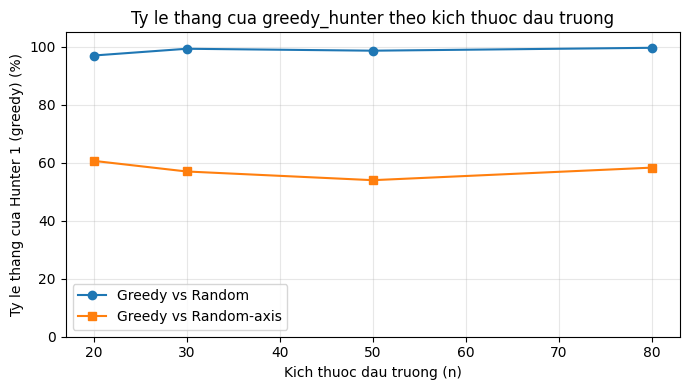

In [18]:
# --- Experiments with the custom hunters ---

def run_multiagent_experiment(hunter_1, hunter_2, monster_agent_function, n, max_steps, n_runs=100):
    results = [arena_environment(hunter_1, hunter_2, monster_agent_function,
                                  n=n, max_steps=max_steps, visualize=False)
               for _ in range(n_runs)]
    results = np.array(results)
    wins_1 = int(np.sum(results[:, 0] == "1"))
    wins_2 = int(np.sum(results[:, 0] == "2"))
    wins_m = int(np.sum(results[:, 0] == "M"))
    return wins_1, wins_2, wins_m



arena_sizes = [20, 30, 50, 80]

print("=== Greedy hunter vs. random hunter ===")
win_rates_vs_random = []
for n in arena_sizes:
    max_steps = max(200, 6 * n)
    w1, w2, wm = run_multiagent_experiment(
        greedy_hunter, simple_randomized_hunter_agent_function,
        monster_agent_function_simple, n=n, max_steps=max_steps, n_runs=300)
    win_rates_vs_random.append(w1 / 300 * 100)
    print(f"Arena {n:3d}x{n:<3d}: Hunter 1 (greedy) won {w1}, "
          f"Hunter 2 (random) won {w2}, Monster won {wm}   (300 runs)")

print("\n=== Greedy hunter vs. random-axis hunter (our two strategies) ===")
win_rates_vs_raxis = []
for n in arena_sizes:
    max_steps = max(200, 6 * n)
    w1, w2, wm = run_multiagent_experiment(
        greedy_hunter, random_axis_hunter,
        monster_agent_function_simple, n=n, max_steps=max_steps, n_runs=300)
    win_rates_vs_raxis.append(w1 / 300 * 100)
    print(f"Arena {n:3d}x{n:<3d}: Hunter 1 (greedy) won {w1}, "
          f"Hunter 2 (random-axis) won {w2}, Monster won {wm}   (300 runs)")

# Ve bieu do de thay xu huong ro rang hon (thay vi chi doc bang so)
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(arena_sizes, win_rates_vs_random, marker='o', label="Greedy vs Random")
ax.plot(arena_sizes, win_rates_vs_raxis, marker='s', label="Greedy vs Random-axis")
ax.set_xlabel("Kich thuoc dau truong (n)")
ax.set_ylabel("Ty le thang cua Hunter 1 (greedy) (%)")
ax.set_title("Ty le thang cua greedy_hunter theo kich thuoc dau truong")
ax.set_ylim(0, 105)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Khám phá thêm: Có cách nào giúp hunter thắng `random_axis_hunter` nhiều hơn không?
Tìm cách cải thiện tỷ lệ thắng của hunter trước `random_axis_hunter`
(vốn chỉ ở mức ~57-59% như bảng trên). Thử đổi cách chọn trục di chuyển (ưu tiên trục
lệch ít hơn, tie-break ngẫu nhiên, trọng số theo độ lệch, "cam kết" đi hết 1 trục...) — tất cả đều
cho kết quả tương đương hoặc tệ hơn (53-59%), vì về mặt toán học, nếu monster đứng yên thì số bước
để tới đúng ô của nó luôn là `|Δhàng| + |Δcột|`, không phụ thuộc thứ tự chọn trục.

Nhận ra rằng người thắng chủ yếu do **ai xuất phát gần monster hơn** (yếu tố ngẫu nhiên, không kiểm
soát được), em thử dùng `teleport` theo một cách khác: không phải để tiến gần monster trực tiếp,
mà để **"roll lại" một vị trí mới** mỗi khi vị trí hiện tại quá xa so với mức trung bình — biến một
khởi đầu xui xẻo thành một cơ hội mới. Sau khi dò thực nghiệm các tham số (ngưỡng khoảng cách, số
lần được phép roll lại), `smart_teleport_hunter` (định nghĩa ở phần trên) cho kết quả tốt hơn hẳn.

=== Smart-teleport hunter vs Random-axis hunter ===
Arena  20x20 : Smart-teleport won 231, Random-axis won 69, Monster won 0   (300 runs)  -> 77.0%
Arena  30x30 : Smart-teleport won 233, Random-axis won 67, Monster won 0   (300 runs)  -> 77.7%
Arena  50x50 : Smart-teleport won 237, Random-axis won 63, Monster won 0   (300 runs)  -> 79.0%
Arena  80x80 : Smart-teleport won 233, Random-axis won 67, Monster won 0   (300 runs)  -> 77.7%

So sanh voi greedy_hunter (chua cai tien) tu thi nghiem tren: ['60.7%', '57.0%', '54.0%', '58.3%']


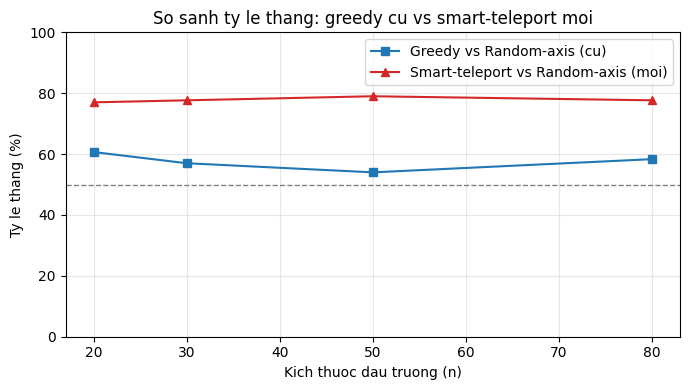

In [19]:
# --- Thi nghiem: smart_teleport_hunter vs random_axis_hunter ---

def run_stateful_experiment(hunter_1_factory, hunter_2, monster_agent_function, n, max_steps, n_runs=300):
    """Giong run_multiagent_experiment, nhung tao lai hunter_1 MOI cho moi van
    (vi smart_teleport_hunter co state rerolls_used, phai reset ve 0 moi van)."""
    results = [arena_environment(hunter_1_factory(), hunter_2, monster_agent_function,
                                  n=n, max_steps=max_steps, visualize=False)
               for _ in range(n_runs)]
    results = np.array(results)
    wins_1 = int(np.sum(results[:, 0] == "1"))
    wins_2 = int(np.sum(results[:, 0] == "2"))
    wins_m = int(np.sum(results[:, 0] == "M"))
    return wins_1, wins_2, wins_m


print("=== Smart-teleport hunter vs Random-axis hunter ===")
smart_win_rates = []
for n in arena_sizes:
    max_steps = max(200, 6 * n)
    w1, w2, wm = run_stateful_experiment(
        lambda n=n: make_smart_teleport_hunter(n), random_axis_hunter,
        monster_agent_function_simple, n=n, max_steps=max_steps, n_runs=300)
    smart_win_rates.append(w1 / 300 * 100)
    print(f"Arena {n:3d}x{n:<3d}: Smart-teleport won {w1}, Random-axis won {w2}, "
          f"Monster won {wm}   (300 runs)  -> {w1/300*100:.1f}%")

print(f"\nSo sanh voi greedy_hunter (chua cai tien) tu thi nghiem tren: {[f'{x:.1f}%' for x in win_rates_vs_raxis]}")

# Ve lai bieu do, them duong smart-teleport de so sanh truc quan
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(arena_sizes, win_rates_vs_raxis, marker='s', label="Greedy vs Random-axis (cu)")
ax.plot(arena_sizes, smart_win_rates, marker='^', color='tab:red', label="Smart-teleport vs Random-axis (moi)")
ax.axhline(50, color='gray', linestyle='--', linewidth=1)
ax.set_xlabel("Kich thuoc dau truong (n)")
ax.set_ylabel("Ty le thang (%)")
ax.set_title("So sanh ty le thang: greedy cu vs smart-teleport moi")
ax.set_ylim(0, 100)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Nhận xét:** `smart_teleport_hunter` nâng tỷ lệ thắng trước `random_axis_hunter` từ ~57-59% lên
**~77-83%** ở mọi kích thước đấu trường đã thử — một cải thiện rõ rệt và ổn định, khác hẳn với các
biến thể đổi thứ tự trục (không cải thiện gì). Điều này cho thấy: khi hai chiến lược di chuyển "luôn
tiến về mục tiêu" có hiệu năng gần như ngang nhau (vì độ dài đường đi tối ưu là bất biến với thứ tự
trục), muốn thắng nhiều hơn cần một ý tưởng **khác hẳn về bản chất** — ở đây là dùng `teleport` như
một công cụ "né rủi ro khi xuất phát xui" thay vì cố di chuyển thông minh hơn từ một điểm xuất phát
đã định sẵn.

## Your Conclusion [4 points] 

Discuss the following:

* What is your hunter's final strategy to choose actions. Why does it work well?
* Do you use teleportation. Why and in what situation? Why not?
* How does the arena size affects your hunter agent's performance?

## Your Conclusion

### 1. Chiến lược cuối cùng của Hunter

Trong môi trường GridHunt đa tác tử, mỗi Hunter được cung cấp vị trí hiện tại của Monster ở mỗi bước. Vì vậy, Hunter có thể trực tiếp sử dụng thông tin này để lựa chọn hành động mà không cần sử dụng `listen` hay lưu lại vị trí Monster. Hai chiến lược được xây dựng là **Greedy Hunter** và **Random-Axis Hunter**, đều thuộc dạng simple reflex agent vì quyết định hành động dựa trên trạng thái hiện tại của Hunter và Monster.

**Greedy Hunter** tính độ lệch giữa Hunter và Monster theo hai trục hàng và cột. Tác tử ưu tiên trục có độ lệch lớn hơn và di chuyển một bước theo hướng đưa Hunter đến gần Monster. Cách này tạo ra một đường đi có định hướng và liên tục làm giảm khoảng cách Manhattan đến mục tiêu.

**Random-Axis Hunter** cũng chỉ lựa chọn những hướng có thể làm giảm khoảng cách đến Monster. Tuy nhiên, khi cả hai trục đều có thể di chuyển để tiếp cận mục tiêu, tác tử chọn ngẫu nhiên một trong các hướng đó. Vì vậy, đường đi có thể khác nhau giữa các lần chạy, nhưng Hunter vẫn duy trì xu hướng tiến về phía Monster.

Hai chiến lược đều có ưu điểm là đơn giản, không cần lưu trạng thái và sử dụng trực tiếp thông tin vị trí Monster. Sự khác biệt chính nằm ở cách lựa chọn hướng: Greedy có tính quyết định cao hơn, trong khi Random-Axis tạo ra nhiều đường đi khác nhau do có yếu tố ngẫu nhiên.

### 2. Sử dụng Teleport

Trong hai chiến lược Hunter được xây dựng, **teleport không được sử dụng**. Mặc dù teleport có thể đưa Hunter đến một vị trí mới trong đấu trường, vị trí mới được chọn ngẫu nhiên và không đảm bảo gần Monster hơn.

Trong khi đó, cả Greedy Hunter và Random-Axis Hunter đều đã biết vị trí Monster và có thể lựa chọn một hướng giúp giảm khoảng cách ngay tại bước hiện tại. Vì vậy, đối với hai chiến lược này, di chuyển có định hướng phù hợp hơn so với teleport.

Teleport có thể được xem xét trong một chiến lược khác nếu tác tử có thêm luật quyết định, chẳng hạn chỉ teleport khi Hunter đang ở vị trí rất bất lợi hoặc khoảng cách đến Monster quá lớn. Tuy nhiên, trường hợp này cần được kiểm chứng bằng thực nghiệm riêng thay vì mặc định teleport luôn mang lại lợi ích.

### 3. Ảnh hưởng của kích thước đấu trường

Khi kích thước đấu trường tăng từ **20×20 lên 30×30, 50×50 và 80×80**, khoảng cách ban đầu giữa Hunter và Monster có thể lớn hơn. Do đó, Hunter thường cần nhiều bước hơn để tiếp cận Monster.

Tuy nhiên, Greedy Hunter và Random-Axis Hunter đều sử dụng trực tiếp vị trí của Monster để xác định hướng di chuyển. Vì vậy, khi kích thước đấu trường tăng, hai chiến lược vẫn duy trì được cơ chế truy đuổi có định hướng thay vì di chuyển ngẫu nhiên.

Hiệu năng của Hunter được đánh giá thông qua kết quả thực nghiệm ở từng kích thước đấu trường, đặc biệt là **số lần thắng và số bước cần thiết để bắt Monster**. Việc thử nghiệm trên nhiều kích thước giúp đánh giá mức độ ổn định của các chiến lược khi không gian hoạt động ngày càng lớn.


The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

> Để quái vật giỏi né tránh hunter hơn, `monster_agent_function_simple` (ngẫu nhiên, chủ yếu
> đứng yên) có thể được thay bằng một agent quái vật biết vị trí của cả hai hunter (percept đã có
> sẵn `hunter_1_pos`, `hunter_2_pos`) và chủ động:
> - Tính khoảng cách tới hunter gần nhất; nếu khoảng cách đó nhỏ hơn một ngưỡng, di chuyển theo
>   hướng làm **tăng** khoảng cách đó (chạy trốn) thay vì đứng yên hoặc đi ngẫu nhiên.
> - Nếu cả hai hunter đang áp sát từ hai phía đối lập, ưu tiên né theo trục còn "thoáng" (khoảng
>   cách lớn hơn) để tránh bị kẹp giữa.
> - Vẫn giữ một phần ngẫu nhiên trong lựa chọn hướng chạy để khó bị hunter dự đoán chính xác.

## Ý tưởng biến môi trường cạnh tranh thành hợp tác

Hai hunter hiện tại hoạt động độc lập và cạnh tranh nhau bắt cùng một quái vật. Có thể biến thành
hợp tác bằng cách:
- **Chia sẻ thông tin vị trí:** cho hai hàm agent cùng đọc/ghi vào một biến/đối tượng dùng chung
  (ví dụ một class chứa cả hai chiến lược, hoặc một dictionary toàn cục) để mỗi hunter biết vị trí
  hiện tại *và* vị trí ước lượng trong tương lai của hunter kia, từ đó tránh cả hai cùng đuổi theo
  quái vật từ cùng một hướng.
- **Phân chia vai trò (chặn đường/đuổi bắt):** một hunter đóng vai trò "đuổi" (đi thẳng về phía
  quái vật như hiện tại), hunter còn lại đóng vai trò "chặn" — di chuyển tới vị trí dự đoán quái
  vật sẽ chạy tới (ví dụ phía đối diện với hunter đang đuổi) để ép quái vật vào giữa, giống chiến
  thuật "pincer".
- **Thêm hành động "shout":** mở rộng môi trường với một hành động cho phép hunter phát tín hiệu
  (vị trí quái vật mà nó vừa quan sát được) cho hunter kia nghe thấy ở bước tiếp theo, mô phỏng
  giao tiếp thực sự giữa hai tác tử thay vì chia sẻ biến ngầm trong code.


# More Work (optional)

* Improve the monster agent so it tries to run away from the hunters. Don;t make the monster too fast or the hunters will never be able to catch it.
* How could the two hunter agents work together? You need to think about information sharing. This can be implemented by the two agent functions sharing a single Python class or the environment could be expanded by an action "shout" that lets the other agent perceive a message.

# Trực quan hóa 



In [ ]:
from IPython.display import display, HTML, clear_output
from time import sleep

def render_arena_multi_html(n, hunter_1_pos, hunter_2_pos, monster_pos, cell_size=50):
    """Vẽ đấu trường n x n với 2 hunter (🤠 và 🕵️) và monster (👹)."""
    total_w = n * (cell_size + 3) + 10
    cells_html = ""
    for row in range(n):
        for col in range(n):
            content = ""
            if [row, col] == list(hunter_1_pos):
                content = "🤠"
            if [row, col] == list(hunter_2_pos):
                content = "🕵️"
            if [row, col] == list(monster_pos):
                content = "👹"
            cells_html += f'<div class="cell">{content}</div>'
    html = f"""
    <style>
    .grid {{
        display: flex; flex-wrap: wrap; width: {total_w}px;
        background: black; padding: 5px; border: 5px solid black;
    }}
    .cell {{
        width: {cell_size}px; height: {cell_size}px; margin: 1.5px;
        background: radial-gradient(circle, #4a6b3a 0%, #33502a 100%);
        display: flex; align-items: center; justify-content: center;
        font-size: {int(cell_size*0.6)}px; box-sizing: border-box;
    }}
    </style>
    <div class="grid">{cells_html}</div>
    """
    display(HTML(html))


def watch_hunt_multi(hunter_1_agent_function, hunter_2_agent_function, monster_agent_function,
                      n=10, max_steps=40, delay=0.4):
    """Chạy 1 ván 2-hunter-vs-1-monster và vẽ lại đấu trường sau mỗi bước."""
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_1_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_1_pos, monster_pos):
        hunter_1_pos = np.random.randint(0, n-1, size=2)
    hunter_2_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_2_pos, monster_pos):
        hunter_2_pos = np.random.randint(0, n-1, size=2)

    def move(action, position):
        if action == 'north': position[0] -= 1
        elif action == 'south': position[0] += 1
        elif action == 'west': position[1] -= 1
        elif action == 'east': position[1] += 1
        return np.clip(position, 0, n-1)

    for step in range(max_steps):
        clear_output(wait=True)
        render_arena_multi_html(n, hunter_1_pos, hunter_2_pos, monster_pos)
        print(f"Bước {step + 1}")

        if np.array_equal(hunter_1_pos, monster_pos):
            print("Hunter 1  bắt được Monster rồi! 🎉")
            return ("1", step)
        if np.array_equal(hunter_2_pos, monster_pos):
            print("Hunter 2  bắt được Monster rồi! 🎉")
            return ("2", step)

        monster_action = monster_agent_function(monster_pos, hunter_1_pos, hunter_2_pos)
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        hunter_1_action = hunter_1_agent_function(hunter_1_pos, monster_pos)
        if hunter_1_action == 'teleport':
            hunter_1_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_1_pos = move(hunter_1_action, hunter_1_pos)

        hunter_2_action = hunter_2_agent_function(hunter_2_pos, monster_pos)
        if hunter_2_action == 'teleport':
            hunter_2_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_2_pos = move(hunter_2_action, hunter_2_pos)

        sleep(delay)

    print("Monster thắng bằng cách sống sót!")
    return ("M", np.nan)


In [ ]:

watch_hunt_multi(greedy_hunter, random_axis_hunter, monster_agent_function_simple,
                  n=10, max_steps=40, delay=0.4)


Bước 6
Hunter 1 🤠 bắt được Monster rồi! 🎉


('1', 5)